# 3. Classification — Πρόβλεψη του HouseStyle

Σε αυτό το notebook απαντάμε στο Βήμα 3(a) της εργασίας. Προσπαθούμε να προβλέψουμε
το στυλ μιας κατοικίας, δηλαδή το **HouseStyle**, χρησιμοποιώντας φυσικά και δομικά
χαρακτηριστικά της. Εκπαιδεύουμε δύο μοντέλα του Scikit-Learn, τον Gaussian Naive
Bayes και τον SVC, και συγκρίνουμε τις προβλέψεις τους με τις πραγματικές κατηγορίες.

Παρουσιάζουμε τις μετρικές με σύντομες γραμμές κειμένου και εξετάζουμε τα αποτελέσματα
με γραφήματα. Χρησιμοποιούμε confusion matrices ως γραφήματα αξιολόγησης και
καμπύλες ROC-AUC, όπως αναφέρει η εκφώνηση.

### 1. Φορτώνουμε τις βιβλιοθήκες

Χρησιμοποιούμε το pandas για να διαβάσουμε τα δεδομένα και το matplotlib για να
σχεδιάσουμε τα γραφήματα. Από το Scikit-Learn παίρνουμε τα εργαλεία για τον
διαχωρισμό των δεδομένων, το scaling, τους δύο ταξινομητές και την αξιολόγησή τους.
Με το Path δημιουργούμε τον φάκελο όπου θα αποθηκεύουμε τα αποτελέσματά μας.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

### 2. Διαβάζουμε τα δεδομένα

Διαβάζουμε το αρχικό train.csv, στο οποίο γνωρίζουμε το HouseStyle κάθε κατοικίας.
Δεν χρησιμοποιούμε εδώ το έτοιμο processed αρχείο, επειδή σε εκείνο έχουμε κάνει
scaling με βάση ολόκληρο το train. Για να αξιολογήσουμε σωστά τα μοντέλα, χωρίζουμε
πρώτα τα δεδομένα και υπολογίζουμε το scaling μόνο από το μέρος εκπαίδευσης.

Δημιουργούμε επίσης τον φάκελο αποτελεσμάτων. Εκτελούμε το notebook από τον φάκελο
notebooks, ώστε το ../ να μας οδηγεί στον βασικό φάκελο του project.

In [2]:
data = pd.read_csv(
    "../data/house-prices/train.csv",
    keep_default_na=False, na_values=["NA", ""]
)

results_dir = Path("../results/classification")
results_dir.mkdir(parents=True, exist_ok=True)

### 3. Εξετάζουμε τις κατηγορίες του HouseStyle

Μετράμε πόσες κατοικίες έχουμε σε κάθε κατηγορία με το value_counts() και
σχεδιάζουμε ένα ραβδόγραμμα. Παρατηρούμε ότι έχουμε πολύ περισσότερα σπίτια
1Story και 2Story από τις υπόλοιπες κατηγορίες.

Λαμβάνουμε υπόψη αυτή τη διαφορά στην αξιολόγηση: δεν αρκούμαστε στο συνολικό
ποσοστό σωστών προβλέψεων, γιατί μπορεί να κρύβει λάθη στις μικρές κατηγορίες.

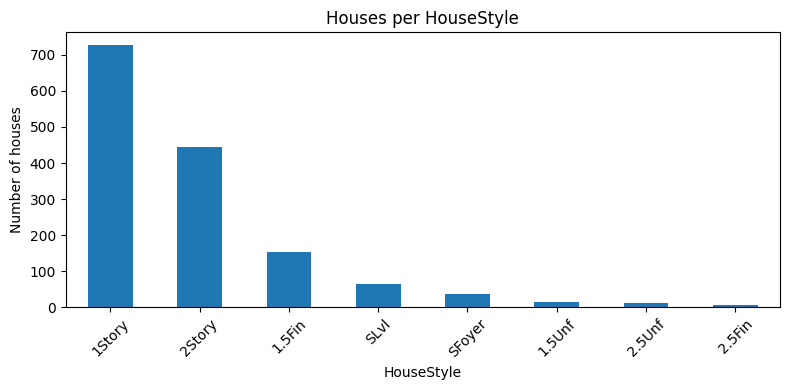

In [3]:
data["HouseStyle"].value_counts().plot(kind="bar", figsize=(8, 4))
plt.title("Houses per HouseStyle")
plt.xlabel("HouseStyle")
plt.ylabel("Number of houses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(results_dir / "house_style_counts.png")
plt.show()

### 4. Επιλέγουμε τι δίνουμε στα μοντέλα και τι προβλέπουμε

Στο **X** κρατάμε δέκα χαρακτηριστικά που περιγράφουν την κατοικία:

- Με τα GrLivArea, 1stFlrSF και 2ndFlrSF περιγράφουμε την επιφάνεια κατοίκησης
  πάνω από το έδαφος και τις επιφάνειες πρώτου και δεύτερου ορόφου.
- Με τα TotalBsmtSF, GarageArea και LotArea περιγράφουμε το μέγεθος υπογείου,
  γκαράζ και οικοπέδου.
- Με τα TotRmsAbvGrd, FullBath και HalfBath περιγράφουμε τον αριθμό δωματίων
  πάνω από το έδαφος, χωρίς μπάνια, και τα πλήρη και μικρά μπάνια πάνω από το έδαφος.
- Με το YearBuilt προσθέτουμε το έτος κατασκευής.

Επιλέγουμε αυτές τις στήλες επειδή περιγράφουν τη δομή και το μέγεθος του σπιτιού,
που μπορεί να σχετίζονται με το στυλ του. Στο **y** κρατάμε το HouseStyle, δηλαδή
τη σωστή απάντηση που θέλουμε να μάθουν τα μοντέλα.

Δεν βάζουμε το HouseStyle στις εισόδους, γιατί έτσι θα δίναμε έτοιμη την απάντηση.
Αφήνουμε επίσης εκτός το Id, την τιμή SalePrice και το MSSubClass. Για το τελευταίο
κάνουμε αυτή την επιλογή επειδή ήδη περιγράφει τον τύπο κατοικίας και επικαλύπτεται
έντονα με τον στόχο μας.

Ελέγχουμε τα κενά με το isna().sum().sum(). Στις συγκεκριμένες στήλες του train
βρίσκουμε μηδέν κενά, οπότε δεν χρειάζεται να συμπληρώσουμε τιμές. Κρατάμε τα
μηδενικά, όπως τη μηδενική επιφάνεια δεύτερου ορόφου, γιατί έχουν πραγματική σημασία.

In [4]:
features = [
    "GrLivArea", "1stFlrSF", "2ndFlrSF", "TotalBsmtSF", "GarageArea",
    "LotArea", "TotRmsAbvGrd", "FullBath", "HalfBath", "YearBuilt"
]
X = data[features]
y = data["HouseStyle"]

print("Κενά στα χαρακτηριστικά:", X.isna().sum().sum())
print("Κενά στο HouseStyle:", y.isna().sum())

Κενά στα χαρακτηριστικά: 0
Κενά στο HouseStyle: 0


### 5. Χωρίζουμε τα δεδομένα

Κρατάμε το 80% για να εκπαιδεύσουμε τα μοντέλα και το 20% για να ελέγξουμε τις
προβλέψεις τους σε κατοικίες που δεν έχουν χρησιμοποιηθεί στην εκπαίδευση.
Με το stratify=y κρατάμε περίπου τις ίδιες αναλογίες κατηγοριών και στα δύο μέρη.
Με το random_state=42 επαναλαμβάνουμε τον ίδιο διαχωρισμό σε κάθε εκτέλεση.

Χρησιμοποιούμε τον ίδιο διαχωρισμό και για τα δύο μοντέλα, ώστε να τα συγκρίνουμε
δίκαια. Με το X_test εννοούμε αυτό το 20% του train.csv, όχι το test.csv του Kaggle.
Δεν χρησιμοποιούμε αυτό το μέρος για να επιλέξουμε τις ρυθμίσεις των μοντέλων.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Κατοικίες για εκπαίδευση:", len(X_train))
print("Κατοικίες για αξιολόγηση:", len(X_test))

Κατοικίες για εκπαίδευση: 1168
Κατοικίες για αξιολόγηση: 292


### 6. Κάνουμε scaling

Φέρνουμε τα χαρακτηριστικά σε συγκρίσιμη κλίμακα, επειδή έχουμε επιφάνειες,
αριθμούς δωματίων και έτη με διαφορετικά μεγέθη. Με το StandardScaler αφαιρούμε
τον μέσο όρο κάθε στήλης και διαιρούμε με την τυπική της απόκλιση.

Με το fit_transform υπολογίζουμε αυτά τα στοιχεία μόνο από το X_train και
μετασχηματίζουμε το X_train. Με το transform εφαρμόζουμε τις ίδιες τιμές στο X_test.
Έτσι δεν χρησιμοποιούμε πληροφορία από το μέρος αξιολόγησης για το scaling.

Κάνουμε αυτό το βήμα κυρίως για τον SVC, που επηρεάζεται από την κλίμακα των εισόδων.
Δίνουμε τις ίδιες μετασχηματισμένες εισόδους και στον Naive Bayes. Δεν χρειάζεται
να κωδικοποιήσουμε τις εισόδους, αφού είναι ήδη αριθμητικές. Κρατάμε το y ως κείμενο,
επειδή και τα δύο μοντέλα δέχονται ονόματα κατηγοριών.

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 7. Εκπαιδεύουμε τον Gaussian Naive Bayes

Δημιουργούμε το πρώτο μοντέλο με το GaussianNB(). Με το fit του δίνουμε τα
χαρακτηριστικά εκπαίδευσης και τις σωστές κατηγορίες. Στη συνέχεια, με το predict
παίρνουμε μία πρόβλεψη HouseStyle για κάθε κατοικία του X_test.

Με αυτή τη μέθοδο εκτιμάμε πόσο πιθανή είναι κάθε κατηγορία με βάση τις τιμές των
χαρακτηριστικών. Κάνουμε την απλουστευτική υπόθεση ότι, μέσα σε κάθε κατηγορία,
τα χαρακτηριστικά είναι ανεξάρτητα και έχουν κανονικές κατανομές. Γνωρίζουμε ότι
οι επιφάνειες συσχετίζονται, οπότε αντιμετωπίζουμε την υπόθεση ως προσέγγιση.

In [7]:
naive_bayes = GaussianNB()
naive_bayes.fit(X_train_scaled, y_train)
nb_predictions = naive_bayes.predict(X_test_scaled)

### 8. Εκπαιδεύουμε τον SVC

Δημιουργούμε το δεύτερο μοντέλο με το SVC(). Με αυτό μαθαίνουμε όρια που διαχωρίζουν
τις κατηγορίες. Επιλέγουμε kernel="rbf" για να μπορούμε να σχηματίσουμε και καμπύλα
όρια, όχι μόνο ευθείες. Κρατάμε τις προεπιλεγμένες τιμές C=1 και gamma="scale". Με το C ρυθμίζουμε
πόσο αυστηρά αντιμετωπίζουμε τα λάθη εκπαίδευσης. Με το gamma ρυθμίζουμε πόσο
τοπικά επηρεάζει κάθε παράδειγμα τα όρια των κατηγοριών. Με την επιλογή "scale"
αφήνουμε τη βιβλιοθήκη να υπολογίσει αυτή την τιμή από τις εισόδους εκπαίδευσης.

Με το class_weight="balanced" δίνουμε μεγαλύτερο βάρος στις σπάνιες κατηγορίες
κατά την εκπαίδευση. Με το probability=True ζητάμε και πιθανότητες, για να
σχεδιάσουμε αργότερα τις ROC καμπύλες. Με το random_state=42 κάνουμε επαναλήψιμο
τον υπολογισμό αυτών των πιθανοτήτων.

Εκπαιδεύουμε με το fit και προβλέπουμε με το predict, όπως στο προηγούμενο μοντέλο.
Χρησιμοποιούμε τον SVC του Scikit-Learn ως δεύτερο ταξινομητή· δεν τον παρουσιάζουμε
ως υλοποίηση LS-SVM.

In [8]:
svm = SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)
svm_predictions = svm.predict(X_test_scaled)

### 9. Μετράμε πόσο καλά προβλέπουμε

Συγκρίνουμε τις προβλέψεις κάθε μοντέλου με το πραγματικό y_test. Υπολογίζουμε:

- **Accuracy:** μετράμε το ποσοστό όλων των προβλέψεων που είναι σωστές.
- **Precision:** ελέγχουμε, από όσα προβλέψαμε ως μία κατηγορία, πόσα ήταν σωστά.
- **Recall:** ελέγχουμε, από όσα ανήκουν πραγματικά σε μία κατηγορία, πόσα βρήκαμε.
- **F1:** συνδυάζουμε precision και recall σε μία τιμή.

Για precision, recall και F1 επιλέγουμε average="macro". Υπολογίζουμε πρώτα τη
μετρική για κάθε κατηγορία και μετά παίρνουμε τον απλό μέσο όρο. Έτσι δίνουμε την
ίδια βαρύτητα στις μικρές και στις μεγάλες κατηγορίες. Με το zero_division=0
εμφανίζουμε μηδέν όταν δεν μπορούμε να υπολογίσουμε μια μετρική λόγω μηδενικού παρονομαστή.

Με το for επαναλαμβάνουμε τις ίδιες πράξεις για τα δύο μοντέλα. Εμφανίζουμε μόνο
τις τέσσερις μετρικές ως κείμενο και κρατάμε τις τιμές για το τελικό γράφημα.

Στο predictions συνδέουμε το όνομα κάθε μοντέλου με τις προβλέψεις του.
Με το .items() παίρνουμε σε κάθε επανάληψη ένα όνομα (name) και τις αντίστοιχες
προβλέψεις (predicted). Με το scores.append(...) προσθέτουμε τις τέσσερις
βαθμολογίες στη λίστα μας. Με το round(..., 3) εμφανίζουμε τρία δεκαδικά ψηφία,
αλλά κρατάμε τις πλήρεις τιμές στη λίστα για την αποθήκευση και το γράφημα.

In [9]:
predictions = {"Naive Bayes": nb_predictions, "SVC": svm_predictions}
scores = []

for name, predicted in predictions.items():
    accuracy = accuracy_score(y_test, predicted)
    precision = precision_score(y_test, predicted, average="macro", zero_division=0)
    recall = recall_score(y_test, predicted, average="macro", zero_division=0)
    f1 = f1_score(y_test, predicted, average="macro", zero_division=0)

    print(name)
    print("Accuracy:", round(accuracy, 3))
    print("Precision macro:", round(precision, 3))
    print("Recall macro:", round(recall, 3))
    print("F1 macro:", round(f1, 3))
    print()
    scores.append([name, accuracy, precision, recall, f1])

Naive Bayes
Accuracy: 0.634
Precision macro: 0.35
Recall macro: 0.503
F1 macro: 0.355

SVC
Accuracy: 0.705
Precision macro: 0.438
Recall macro: 0.702
F1 macro: 0.455



### 10. Εξετάζουμε τα λάθη με confusion matrices

Σχεδιάζουμε ένα γράφημα για κάθε μοντέλο, ώστε να δούμε ποιες κατηγορίες μπερδεύουμε.
Διαβάζουμε στις γραμμές τις πραγματικές κατηγορίες και στις στήλες τις προβλέψεις.
Στη διαγώνιο βλέπουμε τις σωστές προβλέψεις και εκτός διαγωνίου τα λάθη.

Για παράδειγμα, στη γραμμή 1Story και στη στήλη 1.5Unf μετράμε πόσα πραγματικά
1Story προβλέψαμε λανθασμένα ως 1.5Unf. Κρατάμε την ίδια σειρά κατηγοριών στα δύο
γραφήματα, για να τα συγκρίνουμε εύκολα.

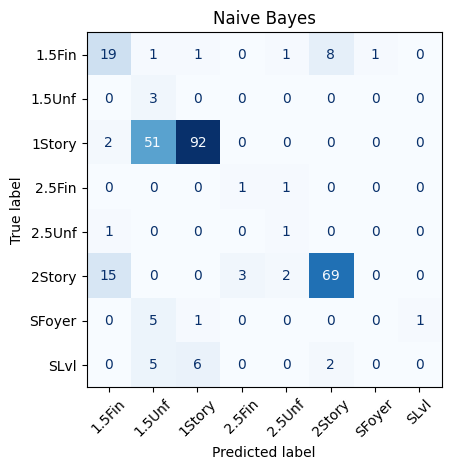

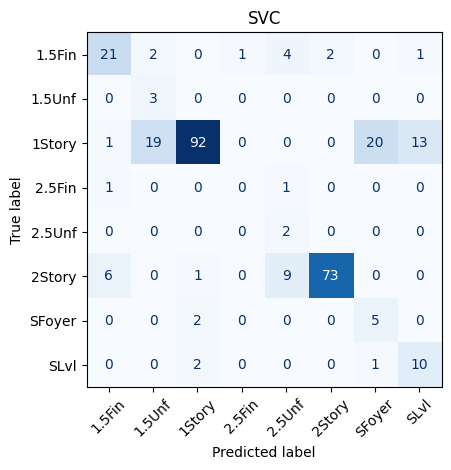

In [10]:
classes = naive_bayes.classes_

for name, predicted in predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=classes, cmap="Blues", xticks_rotation=45, colorbar=False
    )
    plt.title(name)
    plt.tight_layout()
    plt.savefig(results_dir / f"confusion_{name}.png")
    plt.show()

### 11. Σχεδιάζουμε τις ROC καμπύλες

Εξετάζουμε κάθε κατηγορία HouseStyle χωριστά απέναντι σε όλες τις υπόλοιπες.
Με το actual_class = (y_test == label) ελέγχουμε για κάθε σπίτι αν ανήκει
στην κατηγορία που εξετάζουμε. Παίρνουμε True αν ανήκει και False αν δεν ανήκει.
Η roc_curve χρησιμοποιεί αυτές τις απαντήσεις ως 1 και 0.

Με το predict_proba παίρνουμε την πιθανότητα που δίνει το μοντέλο σε κάθε
κατηγορία. Με το enumerate(classes) παίρνουμε τη θέση i και το όνομα label.
Επιλέγουμε με το probabilities[:, i] την αντίστοιχη στήλη πιθανοτήτων για
όλα τα σπίτια. Κρατάμε τη σειρά model.classes_ για να αντιστοιχίσουμε σωστά
τα ονόματα κατηγοριών με τις στήλες.

Με το roc_curve υπολογίζουμε το ποσοστό λανθασμένων θετικών (fpr) και σωστών
θετικών (tpr) για διαφορετικά όρια πιθανότητας. Παίρνουμε επίσης τα thresholds,
δηλαδή τα όρια, αλλά δεν τα χρησιμοποιούμε στο γράφημα.

Με το auc μετράμε την περιοχή κάτω από την καμπύλη. Ερμηνεύουμε μεγαλύτερη
τιμή ως καλύτερο διαχωρισμό της συγκεκριμένης κατηγορίας από τις υπόλοιπες.
Συγκρίνουμε με τη διακεκομμένη γραμμή τυχαίας κατάταξης, που έχει AUC 0.5.
Δεν θεωρούμε το AUC ποσοστό σωστών τελικών προβλέψεων.

Με το εξωτερικό for εξετάζουμε τα δύο μοντέλα και με το εσωτερικό τις οκτώ
κατηγορίες. Στο υπόμνημα γράφουμε το όνομα της κατηγορίας και το AUC με δύο
δεκαδικά, χρησιμοποιώντας το {area:.2f}.

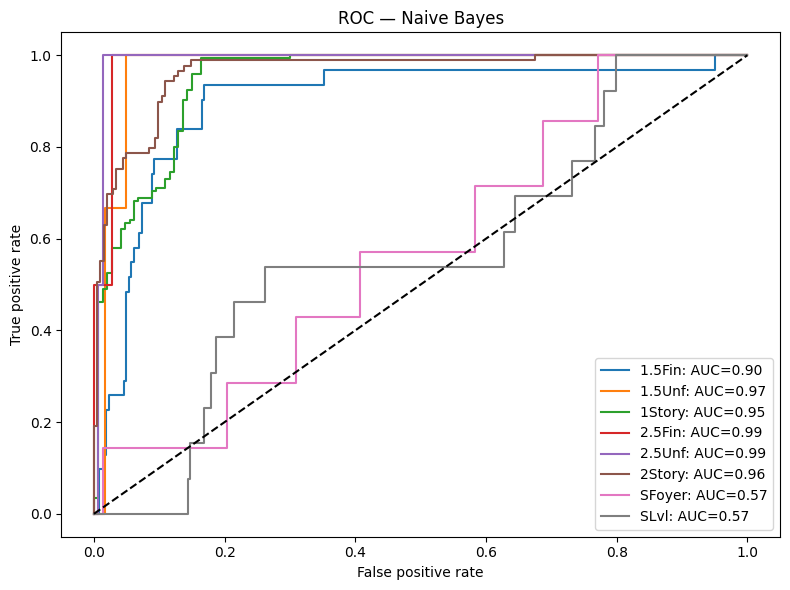

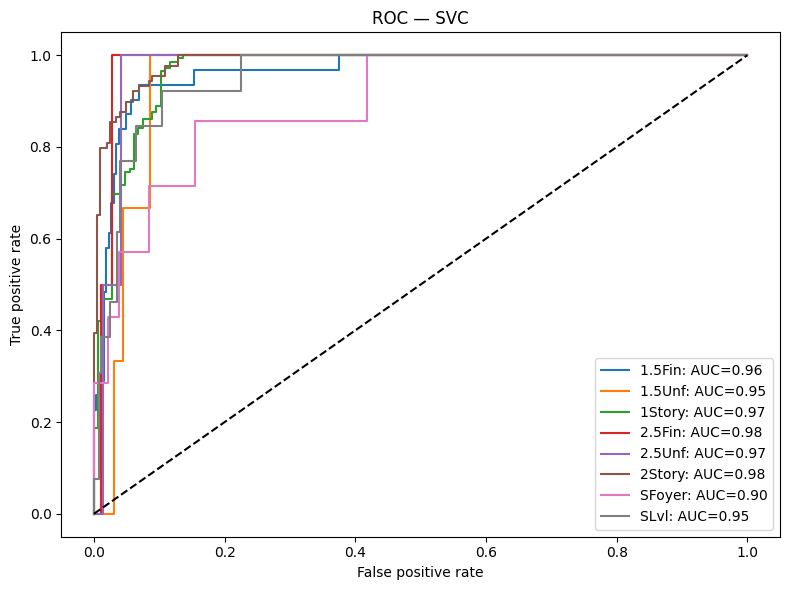

In [11]:
models = {"Naive Bayes": naive_bayes, "SVC": svm}
auc_scores = []

for name, model in models.items():
    classes = model.classes_
    probabilities = model.predict_proba(X_test_scaled)
    plt.figure(figsize=(8, 6))

    for i, label in enumerate(classes):
        actual_class = (y_test == label)
        fpr, tpr, thresholds = roc_curve(actual_class, probabilities[:, i])
        area = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{label}: AUC={area:.2f}")
        auc_scores.append([name, label, area])

    plt.plot([0, 1], [0, 1], "k--")
    plt.title(f"ROC — {name}")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.legend()
    plt.tight_layout()
    plt.savefig(results_dir / f"roc_{name.replace(' ', '_')}.png")
    plt.show()

### 12. Συγκρίνουμε και αποθηκεύουμε τα αποτελέσματα

Χρησιμοποιούμε τις μετρικές που υπολογίσαμε για να σχεδιάσουμε ένα κοινό γράφημα
accuracy και macro F1. Συγκρίνουμε έτσι τη συνολική ορθότητα των προβλέψεων με
την επίδοσή μας όταν δίνουμε ίση βαρύτητα σε κάθε κατηγορία.

Αποθηκεύουμε τις μετρικές και τα AUC σε δύο αρχεία CSV, χωρίς να εμφανίζουμε
τους πίνακες στην έξοδο. Έχουμε ήδη αποθηκεύσει κάθε γράφημα με το savefig.
Χρησιμοποιούμε αυτά τα αποτελέσματα για να τεκμηριώσουμε τη σύγκριση στην αναφορά.

Με το DataFrame οργανώνουμε τις αποθηκευμένες βαθμολογίες σε στήλες και με
το set_index("Model") χρησιμοποιούμε τα ονόματα των μοντέλων ως ετικέτες.
Δεν εμφανίζουμε αυτόν τον πίνακα: τον χρησιμοποιούμε για το γράφημα και το CSV.
Με το index=False στο αρχείο των AUC αποφεύγουμε να αποθηκεύσουμε μια επιπλέον
στήλη με τους αριθμούς των γραμμών.

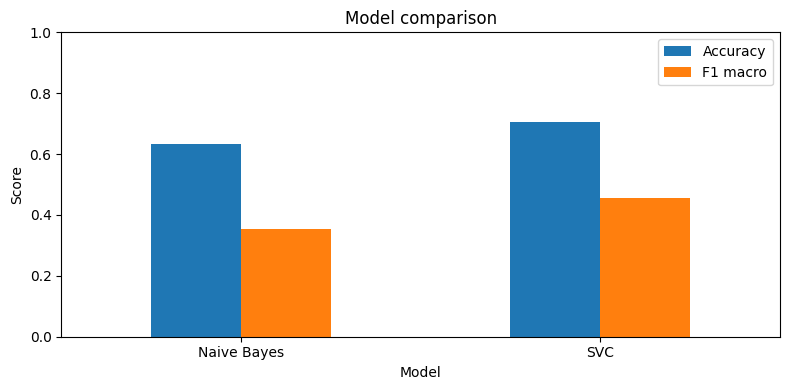

In [12]:
comparison = pd.DataFrame(
    scores,
    columns=["Model", "Accuracy", "Precision macro", "Recall macro", "F1 macro"]
)
comparison = comparison.set_index("Model")

comparison[["Accuracy", "F1 macro"]].plot(kind="bar", figsize=(8, 4))
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(results_dir / "model_comparison.png")
plt.show()

comparison.to_csv(results_dir / "classification_metrics.csv")
auc_results = pd.DataFrame(auc_scores, columns=["Model", "HouseStyle", "AUC"])
auc_results.to_csv(results_dir / "roc_auc_per_class.csv", index=False)

### 13. Τι συμπεραίνουμε

Με τον συγκεκριμένο διαχωρισμό χρησιμοποιούμε 1.168 κατοικίες για εκπαίδευση και
292 για αξιολόγηση. Πετυχαίνουμε **accuracy 63,36% και macro F1 0,355 με τον Naive
Bayes**, ενώ με τον **SVC πετυχαίνουμε accuracy 70,55% και macro F1 0,455**.
Συμπεραίνουμε ότι ο SVC αποδίδει καλύτερα συνολικά σε αυτή τη δοκιμή, αλλά
παρατηρούμε από το macro F1 ότι εξακολουθούμε να δυσκολευόμαστε σε αρκετές κατηγορίες.

Με τον Naive Bayes δεν αναγνωρίζουμε σωστά κανένα από τα 7 SFoyer και τα 13 SLvl.
Επίσης προβλέπουμε λανθασμένα 51 σπίτια 1Story ως 1.5Unf. Με τον SVC αναγνωρίζουμε
σωστά 5 από τα 7 SFoyer και 10 από τα 13 SLvl, αλλά κανένα από τα 2 σπίτια 2.5Fin.
Επομένως δεν θεωρούμε ότι το καλύτερο μοντέλο είναι καλύτερο σε κάθε κατηγορία.

Στις ROC καμπύλες βρίσκουμε για SFoyer και SLvl AUC περίπου 0,898 και 0,954 με
τον SVC, έναντι 0,575 και 0,565 με τον Naive Bayes. Για το 2.5Fin βρίσκουμε υψηλό
AUC με τον SVC, περίπου 0,981, παρότι δεν έχουμε σωστές τελικές προβλέψεις.
Εξηγούμε αυτή τη διαφορά επειδή με το AUC εξετάζουμε την κατάταξη των πιθανοτήτων
μιας κατηγορίας απέναντι στις υπόλοιπες, ενώ με το confusion matrix ελέγχουμε
την τελική επιλογή μίας από τις οκτώ κατηγορίες.

Κρατάμε επιφύλαξη για τις σπάνιες κατηγορίες, επειδή έχουμε μόνο δύο ή τρία
παραδείγματα για ορισμένες από αυτές στο test. Αναγνωρίζουμε επίσης ότι δοκιμάσαμε
έναν συγκεκριμένο διαχωρισμό και δεν γενικεύουμε το αποτέλεσμα σε κάθε πιθανό
σύνολο δεδομένων. Αν αλλάξουμε δεδομένα ή ρυθμίσεις, ενημερώνουμε και τα συμπεράσματα.

Στην τελική αναφορά συμπεριλαμβάνουμε τις μετρικές, τα γραφήματα και την ερμηνεία
τους, ώστε να παρουσιάσουμε ολοκληρωμένα το Βήμα 3(a).

### Πηγές

Βασιζόμαστε στην εκφώνηση και στις περιγραφές στηλών του data_description.txt.
